In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
import data_utils_all as du
from pathlib import Path

In [2]:
# prepping for later saving (make folder named cleaned inside dataset folder)
# if you want to save it elsewhere, modify OUT_DIR, but DO NOT push your changes! 
# otherwise Ada cries :(

OUT_DIR = Path("../dataset/cleaned")         
OUT_DIR.mkdir(parents=True, exist_ok=True)

def save(df: pd.DataFrame, name: str) -> Path:
    path = OUT_DIR / f"{Path(name).stem}.csv"   # strips any folder or extension passed by mistake
    df.to_csv(path, index=False, mode="x")
    print(f"Saved dataset from {path_in} here: {path}!")

In [ ]:
# see the data_utils_all.py file 
# load_clean function loads and does basic cleaning
# all cleaning options can be turned on and off in the function

path_in = "../dataset/Iisingintie_Acc1_m801_RDMC_2026-05-06_124454.txt"
new_file_name = "Iisingintie2"
# here you can drop one of the RBCSV values
# if you enter 60 -> 80 gets dropped, and vice versa 
RBCSV = 60


df = du.load_clean(path_in, trim=False, continuous=False, transfix=False)

df.head()

../dataset/Iisingintie_Acc1_m801_RDMC_2026-05-06_124454.txt: 83597 rows


,Timer(ms),Loc(m),East(m),North(m),CElev(m),Roll(deg),Pitch(deg),Yaw(deg),AccX,AccY,AccZ,GyrX,GyrY,GyrZ,RBCSV_80(cf),RBCSV_60(cf),posneg,vaikeus,muu,Speed_kmh
0,45900476.5,3760.479,426295.583,7414096.205,109.111,2.0162,-1.8280,5.3424,0.30559,0.35245,9.83279,-0.00746,0.00199,0.00196,7.16884,7.1267,0.0,0.0,0.0,0.2196
1,45900479.0,3760.479,426295.583,7414096.205,109.112,2.0173,-1.8276,5.3428,0.28938,0.37702,9.83549,0.00233,0.00402,-0.00203,7.16884,7.1267,0.0,0.0,0.0,0.2196
2,45900474.0,3760.479,426295.583,7414096.205,109.111,2.0165,-1.8282,5.3417,0.31479,0.37302,9.79574,-0.00510,0.00201,0.00173,7.16884,7.1267,0.0,0.0,0.0,0.2196
3,45900481.5,3760.479,426295.583,7414096.205,109.112,2.0172,-1.8274,5.3428,0.32006,0.39893,9.81955,-0.00597,0.00235,-0.00437,7.16884,7.1267,0.0,0.0,0.0,0.2196
4,45900471.5,3760.479,426295.583,7414096.205,109.111,2.0165,-1.8283,5.3408,0.31482,0.38664,9.83676,-0.00245,0.00137,-0.00626,7.16884,7.1267,0.0,0.0,0.0,0.2196


In [4]:
# trimming the ends of the data 
# sensor and timestamps are off and unreliable here, so they need to go
trimmed = du.trim_ends(df)

print("Kept Loc:", round(trimmed["Loc(m)"].min()), "-", round(trimmed["Loc(m)"].max()))
print("Rows:", len(df), "->", len(trimmed))

Kept Loc: 3805 - 6882
Rows: 83597 -> 75465


In [5]:
def fix_transitions(dfcol, threshold=0.05, settle=3, tol=0.02):
    """
    Label a noisy signal with clean whole numbers (baseline 0).
    Rise: whole ramp gets the level it settles on. Drop: labelled 0.
    Stable rows: rounded.

    threshold: row-to-row change that counts as movement
    settle:    still rows needed to count as settled
    tol:       max distance from a whole number to count as on it
    """
    v = dfcol.to_numpy(dtype=float)
    out = np.rint(v).astype(int)                 # default: rounded values
    diff = np.diff(v, prepend=v[0])              # change from previous row
    changed = np.abs(diff) > threshold           # True where the signal moved

    start, direction, quiet = None, 0, 0         # transition start, +1 rise / -1 drop, still rows
    for i in range(len(v)):
        quiet = 0 if changed[i] else quiet + 1

        if changed[i] and start is None:         # a jump begins a transition
            start = i
            direction = 1 if diff[i] > 0 else -1

        # settled: no movement for `settle` rows AND on a whole number
        if start is not None and quiet >= settle and abs(v[i] - round(v[i])) <= tol:
            out[start:i + 1] = round(v[i]) if direction > 0 else 0
            start = None

    if start is not None:                        # data ended mid-transition
        out[start:] = max(round(v[-1]), 0) if direction > 0 else 0

    return pd.Series(out, index=dfcol.index)

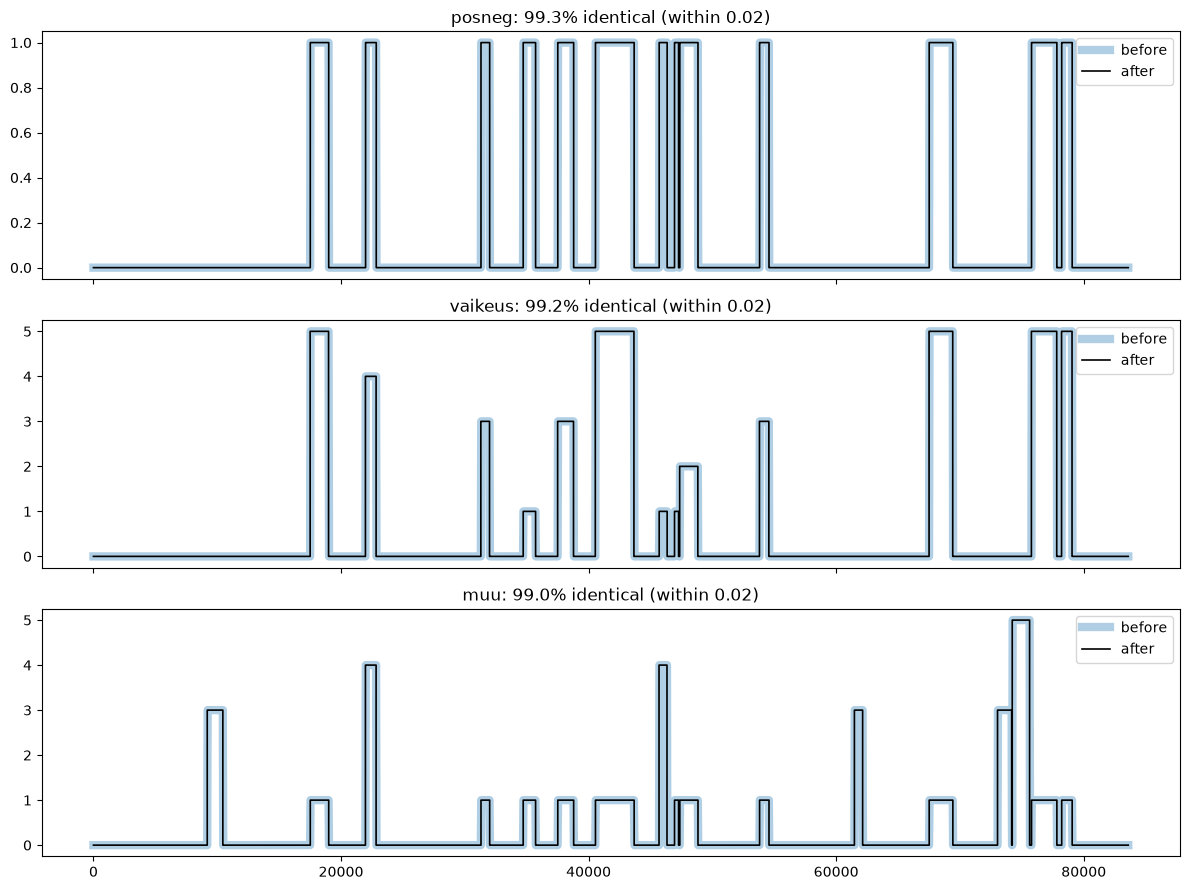

In [6]:
cols_to_fix = ['posneg', 'vaikeus', 'muu']
df_cleaned = df.copy()

for col in cols_to_fix:
    df_cleaned[col] = fix_transitions(df_cleaned[col], threshold=0.05, settle=3, tol=0.02)


def plot_before_after(df_before, df_after, columns, tol=0.02):
    fig, axes = plt.subplots(len(columns), 1, figsize=(12, 3 * len(columns)), sharex=True, squeeze=False)
    for ax, col in zip(axes[:, 0], columns):
        b, a = df_before[col], df_after[col]
        same = (b - a).abs() <= tol

        # before: thick and light underneath, after: thin and dark on top.
        # Where they overlap, the thin line sits inside the thick one.
        ax.plot(b.index, b, color="tab:blue", linewidth=6, alpha=0.35, label="before")
        ax.step(a.index, a, where="post", color="black", linewidth=1.2, label="after")

        # red dots mark rows where they differ by more than tol -> uncomment to see where the function has fixed stuff
        # important that the red dots only show up in up/down slopes -> these are what needs to be changed
        # ax.scatter(b.index[~same], b[~same], color="red", s=18, zorder=3, label="differs")

        ax.set_title(f"{col}: {same.mean():.1%} identical (within {tol})")
        ax.legend(loc="upper right")
    plt.tight_layout()
    plt.show()

plot_before_after(df, df_cleaned, cols_to_fix)

In [7]:
# this looks good, applying ficit to the actual dataset
# not really needed for all the columns since some are getting dropped with no use anyway, but may as well 


for col in cols_to_fix:
    df[col] = fix_transitions(df[col], threshold=0.05, settle=3, tol=0.02, )

In [8]:
# creating frostbump column that is just does 0/1
# this makes muu redundant, as well as posneg & vaikeus
 
df["Frostbumps"] = (
    (df["muu"] == 1) |
    (df["muu"] == 2)
).astype(int)

df["Frostbumps"]

0        0
1        0
2        0
3        0
4        0
        ..
83592    0
83593    0
83594    0
83595    0
83596    0
Name: Frostbumps, Length: 83597, dtype: int64

In [ ]:
# selecting one of the RBSCV values

if RBCSV == 80:
    df = df.drop(["posneg","muu","vaikeus", "East(m)", "North(m)", "RBCSV_60(cf)"], axis=1)

elif RBCSV == 60:
    df = df.drop(["posneg","muu","vaikeus", "East(m)", "North(m)", "RBCSV_60(cf)", "RBCSV_80(cf)"], axis=1)

else:
    raise ValueError("You left out")


In [10]:
# running saving function created in the beginning
# make sure you change the name for how you want to save it here! 
# the function adds the csv, just put the raw filename here

try:
    save(df, new_file_name)

except FileExistsError:
    print("Dumbdumb, you forgot to define a new name for the saved file :(")


Saved dataset from ../dataset/Iisingintie_Acc1_m801_RDMC_2026-05-06_124454.txt here: ../dataset/cleaned/Iisingintie2.csv!
